# KQC Demo — four coupled Swissmons, two probe lines, charge and flux lines (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' demonstration chip (`chips/demo.py`, class `Demo`; © IQM Finland Oy, GPL-3.0,
<https://github.com/iqm-finland/KQCircuits>; local copy `other-libs/KQCircuits-main/.../kqcircuits/chips/demo.py`).
Four Swissmon qubits sit at the corners of a 3560 × 4000 µm rectangle and are coupled in a ring by four CPW
couplers between their side couplers. Each qubit has a λ/2 readout resonator ending on a finger capacitor on a T
in a probe line (two probe lines, two qubits each, each with a tapered finger capacitor at its input), a charge
line and a flux line, all from an ARD24 sample holder. Two junction-test arrays sit at the sides.

This notebook **rebuilds** that chip with our components, routes, netlist and LOM on the Quantcore PDK — it is
not a replica. We distribute the rebuild under GPL-3.0. The table says what is kept and what the PDK changes.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` (dicing edge, IQM markers, labels) | same 10 × 10 mm (the ARD24 launchers sit on its edges; it does not fit the 7.5 mm die), Quantcore die frame: L dicing markers, 3 × 3 alignment grids, chip boundary, device ID "Demo" |
| launchers | ARD24, `launcher_indent` 680 µm (outer etch 21 µm from the edge) | ARD24, indent **759 µm** from the PDK pad rule (outer etch `frame.pad_edge` = 100 µm from the edge, 79 µm further in than KQC's); same pad assignment |
| substrate | KQC simulation default silicon, εr 11.45 | sapphire 650 µm, εr 10.25 |
| junctions | KQC Manhattan SQUIDs (assumed L_J 16 nH) | Quantcore Nb/AlOx/Nb trilayer SQUIDs, 2 × 0.25 × 0.6 µm, R_n 45 kΩ in parallel, L_J 6.73 nH |
| cheese | KQC's whole-area ground grid (`with_grid`, 5 µm holes on a 10 µm step, in KQC's mask builds) | **the original wins:** KQC's grid (`with_grid=True`), so no PDK band is drawn |
| elements, positions, routes | — | kept: every KQC element with the source's parameters, positions and orientations; waypoints derived from the launcher ports |
| placement | centred | centred (checked below, no shift) |

**Simplified:** the readout meanders are fitted by our router on the 1100 µm segment instead of a KQC `Meander`
of fixed width; the couplers' and probe lines' extra airbridges (`n_bridges`) are left out. The readouts end on a
capacitor at both ends, so they are λ/2 (≈ 11 GHz for 5000 µm on sapphire), as in the source.

The notebook walks through the build step by step: setup and the PDK → die and frame → launchers → components →
routes → DRC → netlist → LOM simulation → FEM jobs → results back → one design change → fab export →
snapshots → summary.

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; set it to `True` to solve the jobs in a new batch
AEDT 2024 R1 (if one is installed). `FULL_FAB = False` skips the slow corner rounding of the 800 000 grid holes in
the fab step (`qcc mask` does the full file).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc")               # design JSON + final snapshots
STEPS = Path("build/snapshots/demo")             # step-by-step snapshots (build/ is not kept in the repo)

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the SQUIDs, and the
cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The junction from the PDK rule.** KQC draws a SQUID in every Swissmon. `trilayer_junction` turns it into the
Quantcore trilayer SQUID: two junctions whose straight finger is KQC's `junction_width` (the bent finger stays at
the PDK 0.6 µm). With the nominal L_J (6.73 nH, the 0.5 × 0.6 µm junction at R_n 45 kΩ) as the SQUID's parallel
total, each junction is 0.25 × 0.6 µm. `JJ_PARAMS` go on the cell, `JUNCTION` (L_J, C_J) is what the LOM and the
FEM junction ports use.

In [4]:
LJ_PDK = trilayer_junction("Swissmon")[1]["Lj_nH"]          # PDK nominal L_J (0.5 × 0.6 µm junction, R_n 45 kΩ)
JJ_PARAMS, JUNCTION = trilayer_junction("Swissmon", lj_nH=LJ_PDK, squid=True)
print("cell parameters:", JJ_PARAMS)
print("LOM junction:   ", JUNCTION)

cell parameters: {'junction_type': 'Quantcore Squid', 'junction_width': 0.25}
LOM junction:    {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


## 3 · The die and its frame

`Designer(...)` starts the chip: the 10 × 10 mm box, the ARD24 sample-holder launchers with KQC's assignment for
the Demo chip (pad numbers clockwise from the top-left; only the assigned ones are drawn) and the chip name
"Demo", which the Quantcore frame writes as the device ID on a free edge. `with_grid=True` asks for KQC's
whole-area ground grid (the original's cheese): the PDK band is then not added (chip `cheese` stays `"auto"`).

The frame itself is the PDK default: L dicing markers on 1000/0 at the corners, 3 × 3 alignment grids on 1001/0
and the chip boundary on 100/0. KQC's own `ChipFrame` is not drawn.

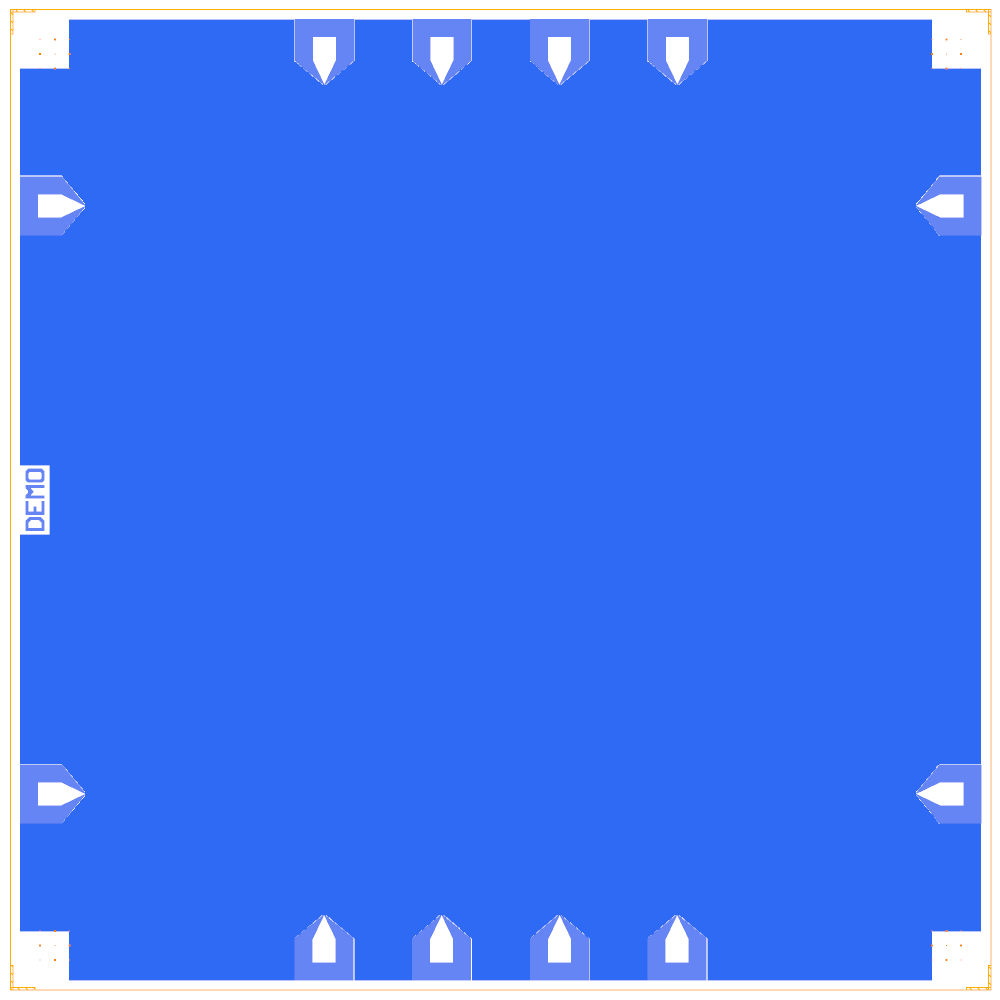

In [5]:
# KQC launcher assignment of the Demo chip (ARD24 pad numbers, clockwise from the top-left); only these are drawn
pads = {2: "FL-QB1", 3: "PL-1-IN", 4: "PL-1-OUT", 5: "FL-QB2", 7: "DL-QB2", 12: "DL-QB4", 14: "FL-QB4",
        15: "PL-2-IN", 16: "PL-2-OUT", 17: "FL-QB3", 19: "DL-QB3", 24: "DL-QB1"}
d = Designer("demo", box=(0, 0, 10000, 10000), launchers={"type": "ARD24", "assign": pads},
             chip={"name_chip": "Demo", "with_grid": True}, live=LIVE)
L = {name: f"chip.{name}" for name in pads.values()}       # launcher ports, referenced as "chip.<name>"
snap(d, STEPS / "1_die.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420);

## 4 · Launchers and the pad rule

**PDK rule:** a bond pad's or launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge.
For KQC sample-holder launchers the Designer applies it by computing `launcher_indent` (die edge → launcher
port): RF launcher = 100 µm + taper (240 µm) + pad (240 µm) + gap (179 µm) = **759 µm** (KQC: 680 µm, i.e. the
outer edge 21 µm from the edge). Every route below starts from these ports, so nothing else moves with the
rule. (Stand-alone pads, e.g. a `BondPad`, take `edge="auto"` in `d.add` instead; this chip has none.)

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| chip.FL-QB1 | launcher port | n | port 759 µm in (indent from the rule) | ✓ |
| chip.PL-1-IN | launcher port | n | port 759 µm in (indent from the rule) | ✓ |
| chip.PL-1-OUT | launcher port | n | port 759 µm in (indent from the rule) | ✓ |
| chip.FL-QB2 | launcher port | n | port 759 µm in (indent from the rule) | ✓ |
| chip.DL-QB2 | launcher port | e | port 759 µm in (indent from the rule) | ✓ |
| chip.DL-QB4 | launcher port | e | port 759 µm in (indent from the rule) | ✓ |
| chip.FL-QB4 | launcher port | s | port 759 µm in (indent from the rule) | ✓ |
| chip.PL-2-IN | launcher port | s | port 759 µm in (indent from the rule) | ✓ |
| chip.PL-2-OUT | launcher port | s | port 759 µm in (indent from the rule) | ✓ |
| chip.FL-QB3 | launcher port | s | port 759 µm in (indent from the rule) | ✓ |
| chip.DL-QB3 | launcher port | w | port 759 µm in (indent from the rule) | ✓ |
| chip.DL-QB1 | launcher port | w | port 759 µm in (indent from the rule) | ✓ |

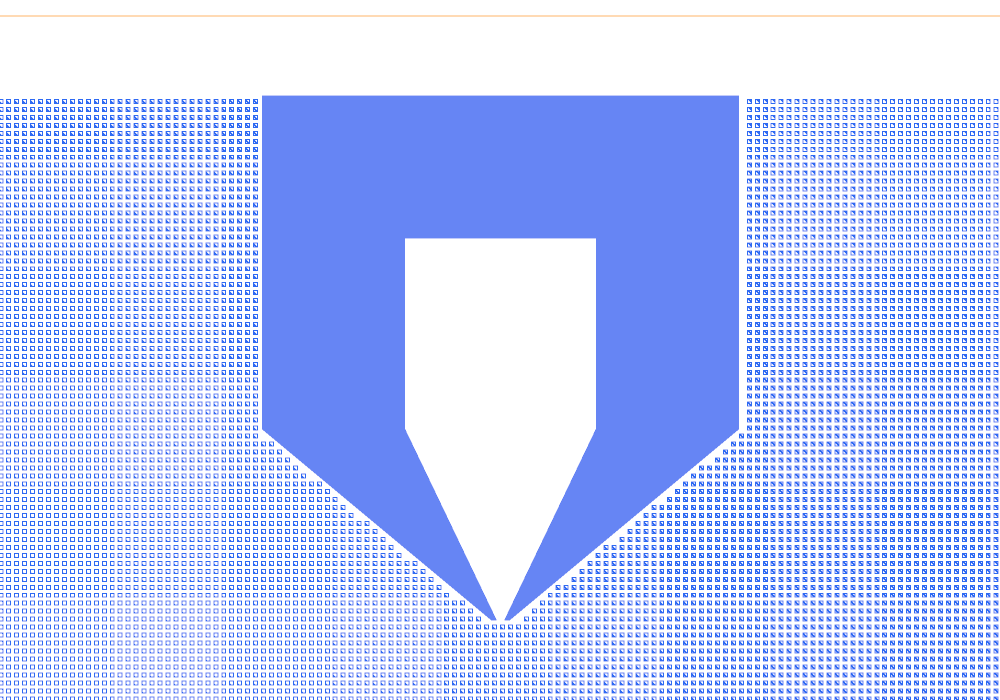

In [6]:
display(Markdown(pads_md(d)))
x, y = port_xy(d, L["PL-1-IN"])
snap(d, STEPS / "2_launcher.png", box=(x - 400, y - 100, x + 400, 10000 + 20), size=(1000, 700), width=420);

## 5 · Components

**Qubits.** Four KQC `Swissmon`s at KQC's positions, mirrored / rotated as KQC's `DTrans(0, True, …)`,
`DTrans(2, False, …)`, …: three couplers of 120 µm (`cpl_length`), port widths 4/10/4 µm, the standard flux line.
Ports: `cplr0`–`cplr2` (couplers), `drive` (charge line), `flux`. The SQUID at the top arm carries the trilayer
junction parameters from step 2.

The helpers: `port_xy(d, ref)` is the absolute position of a port, `corner(ref)` is KQC's `"<port>_corner"`
refpoint (one turn radius out along the port), `shift_away(p, base, dist)` moves a point further from a centre.

In [7]:
def xy(ref):                                     # absolute port position
    return port_xy(d, ref)


def corner(ref, dist=100.0):                     # KQC "<port>_corner": one turn radius out along the port
    x, y, a = port_info(d, ref)
    return (x + dist * math.cos(math.radians(a)), y + dist * math.sin(math.radians(a)))


# qubits: (x, y, rotation, mirror) as KQC's DTrans(0, True, …), DTrans(2, False, …), …
base = {"QB1": (3220, 7000, 0, True), "QB2": (6780, 7000, 180, False),
        "QB3": (3220, 3000, 0, False), "QB4": (6780, 3000, 180, True)}
with d.batch():
    qb = {n: d.add(n, "Swissmon", at=(x, y), rot=r, mirror=m, cpl_length=[120, 120, 120], port_width=[4, 10, 4],
                   junction=JUNCTION, **JJ_PARAMS) for n, (x, y, r, m) in base.items()}
print(qb["QB1"])

<Swissmon QB1 ports=['cplr0', 'cplr1', 'cplr2', 'drive', 'flux']>


**Readout capacitors and probe-line T's.** Each readout resonator ends on a `FingerCapacitorSquare` (4, 8, 5 and
7 fingers) placed 600 µm out of the qubit's coupler 1, 300 µm sideways and 1100 µm further (KQC's readout path).
A `WaveguideCoplanarSplitter` T is snapped to the capacitor's far port: the probe line runs through its
`left`/`right` arms. Each probe line starts with a `FingerCapacitorTaper` (6 / 3 fingers, 20 µm taper) 2000 µm
from its first T. `add_aligned` places a cell by one of its ports (KQC's `insert_cell(..., align=port)`).

**Junction-test arrays.** KQC's `JunctionTestPads` at both sides, with the same trilayer SQUID.

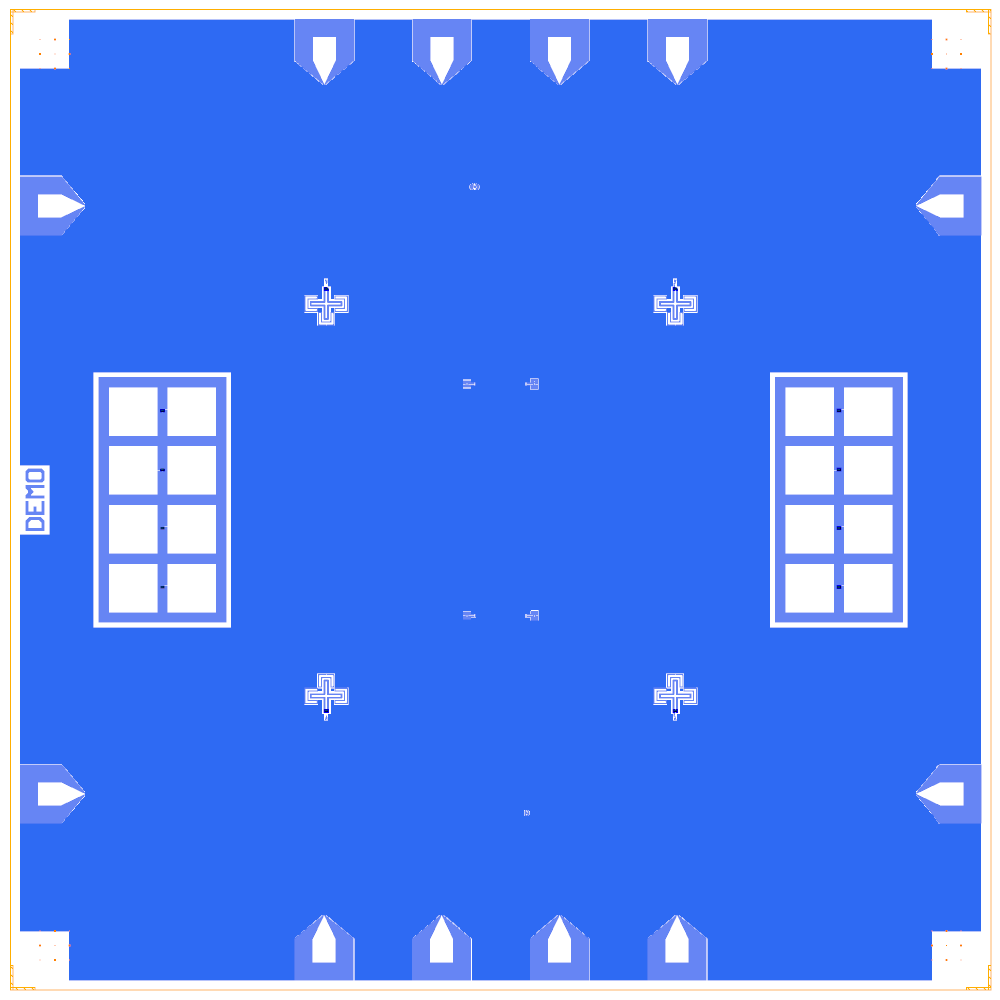

In [8]:
RR_PATH = {}                                     # readout waypoints, used by the routes in step 6
with d.batch():
    for i, mirrored, fingers in ((1, False, 4), (2, True, 8), (3, False, 5), (4, True, 7)):
        s = -1 if mirrored else 1
        p2 = shift_away(xy(f"QB{i}.cplr1"), base[f"QB{i}"][:2], 600)   # 600 µm out of coupler 1
        p3 = (p2[0] + 300 * s, p2[1])                                    # 300 µm sideways
        cap = add_aligned(d, f"RC{i}", "FingerCapacitorSquare", "a", (p3[0] + 1100 * s, p3[1]),
                          rot=180 if mirrored else 0, finger_number=fingers)
        d.add(f"PL{i}", "WaveguideCoplanarSplitter", snap="bottom", to=cap.b, lengths=[11, 11, 41],
              port_names=["right", "left", "bottom"])
        RR_PATH[i] = [p2, p3]
    for pl, qa, mirrored, fingers in (("PL-1", 1, False, 6), ("PL-2", 4, True, 3)):
        lx, ly = xy(f"PL{qa}.left")
        d.add(f"{pl}-C", "FingerCapacitorTaper", at=(lx, ly + (-2000 if mirrored else 2000)),
              rot=90 if mirrored else 270, finger_number=fingers, taper_length=20)
    JTP = "kqcircuits.test_structures.junction_test_pads.junction_test_pads.JunctionTestPads"
    for name, x in (("JT_W", 900), ("JT_E", 7800)):
        d.add(name, JTP, at=(x, 3750), margin=50, area_height=2500, **JJ_PARAMS)
snap(d, STEPS / "3_components.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420);

## 6 · Routes

Routes join two ports with CPW (PDK default a = 10, b = 6 µm, r = 100 µm unless given). `nodes` are waypoints;
`meander=` fits a meander of that total length; `term2=` leaves an open end of that gap; `d.waypoint(...,
airbridge=True)` puts an airbridge where a line crosses another.

**Ring couplers** (a = 4, b = 9 µm) between the qubits' side couplers, 400 µm straight out of each qubit.
**Charge lines** (6 µm open end at the qubit's drive port) and **flux lines**, straight from the launcher corner as
in KQC: every waypoint is derived from a launcher port (`corner(L[...])`), so the pad rule's 79 µm shift of the
launchers carries through (with KQC's hard-coded coordinates the first waypoint would sit 21 µm from the
moved launcher port, shorter than one bend radius, and the route would fail).

In [9]:
with d.batch():
    for a, b, k in ((1, 2, 2), (2, 4, 0), (4, 3, 2), (3, 1, 0)):
        pa, pb = f"QB{a}.cplr{k}", f"QB{b}.cplr{k}"
        d.route(f"CP{a}{b}", pa, pb, a=4, b=9, nodes=[shift_away(xy(pa), base[f"QB{a}"][:2], 400),
                                                     shift_away(xy(pb), base[f"QB{b}"][:2], 400)])
    for i in range(1, 5):
        d.route(f"DL{i}", L[f"DL-QB{i}"], qb[f"QB{i}"].drive, nodes=[corner(L[f"DL-QB{i}"])], term2=6)
        d.route(f"FLX{i}", L[f"FL-QB{i}"], qb[f"QB{i}"].flux, nodes=[corner(L[f"FL-QB{i}"]), corner(f"QB{i}.flux")])

**Readout resonators.** From coupler 1 along KQC's path (600 µm out, 300 µm sideways) and then a meander over the
1100 µm segment to the capacitor, with total lengths 5000, 5100, 5200, 5300 µm (λ/2 between two capacitors).

**Probe lines.** Input launcher → tapered capacitor → T of qubit a → T of qubit b → output launcher; the first and
last legs start at the launcher's corner, turn along the T's x, and cross the ring coupler on an airbridge at the
qubits' y.

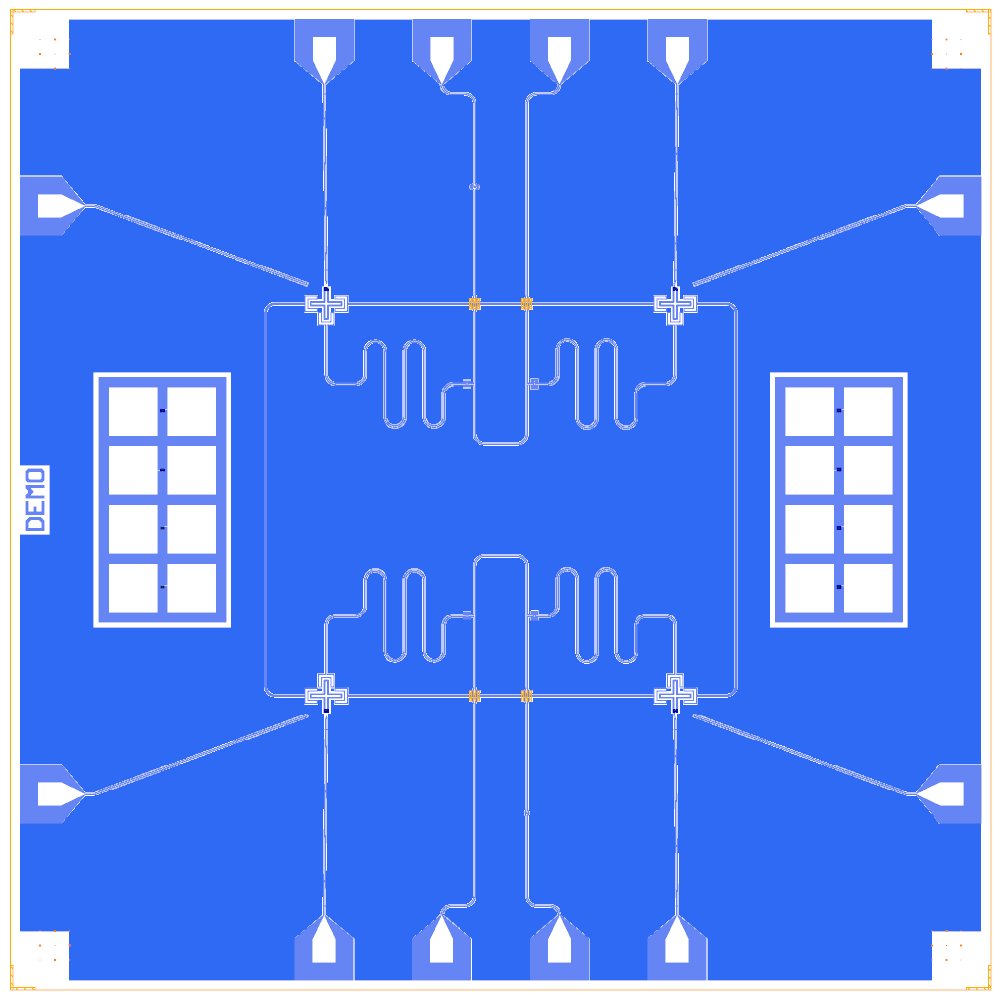

{'RR1': 5000.0, 'RR2': 5100.0, 'RR3': 5200.0, 'RR4': 5300.0}


In [10]:
lengths = {1: 5000, 2: 5100, 3: 5200, 4: 5300}
with d.batch():
    for i in range(1, 5):
        d.route(f"RR{i}", qb[f"QB{i}"].cplr1, f"RC{i}.a", nodes=RR_PATH[i], meander=lengths[i])
    for pl, qa, qbn in (("PL-1", 1, 2), ("PL-2", 4, 3)):
        lx, _ = xy(f"PL{qa}.left")
        c_in = corner(L[f"{pl}-IN"])
        d.route(f"{pl}-1", L[f"{pl}-IN"], f"{pl}-C.a", nodes=[c_in, (lx, c_in[1])])
        d.route(f"{pl}-2", f"{pl}-C.b", f"PL{qa}.left", nodes=[d.waypoint((lx, base[f"QB{qa}"][1]), airbridge=True)])
        d.route(f"{pl}-3", f"PL{qa}.right", f"PL{qbn}.left",
                nodes=[corner(f"PL{qa}.right", 600), corner(f"PL{qbn}.left", 600)])
        rx, _ = xy(f"PL{qbn}.right")
        c_out = corner(L[f"{pl}-OUT"])
        d.route(f"{pl}-4", L[f"{pl}-OUT"], f"PL{qbn}.right",
                nodes=[c_out, (rx, c_out[1]), d.waypoint((rx, base[f"QB{qbn}"][1]), airbridge=True)])
snap(d, STEPS / "4_routes.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)
print({k: round(v, 1) for k, v in d.result.route_lengths().items() if k.startswith("RR")})

**Sim groups and centring.** A sim group names a FEM sub-problem: each qubit with its readout and capacitor (Q3D
C-matrix, 300 µm margin) and the four-qubit ring. `center_in_die` checks that the content sits centred in the
die (PDK placement rule) and shifts it if it is more than 50 µm off — here it is centred, so nothing moves. Then
the design is saved: `demo.json` is what DRC, LOM, FEM and `qcc` read.

In [11]:
for i in range(1, 5):
    d.sim_group(f"QB{i}_RR{i}", [f"QB{i}", f"RR{i}", f"RC{i}"], margin_um=300, analyses=["q3d_cmatrix"])
d.sim_group("ring", ["QB1", "QB2", "QB3", "QB4", "CP12", "CP24", "CP43", "CP31"], analyses=["q3d_cmatrix"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN = d.save(OUT / "demo.json")
print(d, "→", DESIGN)

centring shift (µm): (0.0, 0.0)


<Designer demo: 16 instances, 24 routes, live=False> → examples\designs\kqc\demo.json


## 7 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices.

`pdk_rn` judges the device R_n: for a SQUID that is the two junctions in parallel (what a probe station measures
across it), 45 kΩ here — inside the 40–50 kΩ window, so the SQUIDs are not flagged.

In [12]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 0 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|

| check | value |
|---|---|
| cheese | the original design's own (or none) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Squid × 4 |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: each component's LOM model maps its ports to circuit nodes,
routes join nodes (or become transmission-line resonators), launchers are 50 Ω ports or drive / flux controls.

For the Swissmon: an island node with C to ground and the SQUID to ground, one coupler node per side coupler
(C_g to the island, C to ground). A ring coupler joins two coupler nodes into one conductor; a readout route
between two capacitors with a meander becomes a λ/2 `TLres`; charge and flux lines are drive / flux controls on
the SQUIDs. The first table lists the nodes and the FEM nets that form each one; the second the branches with
their component estimates.

In [13]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**QB1's ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith("QB1."))))

**21 nodes · 66 branches · 8 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `QB1` | `QB1.island` |
| `QB1.cplr0` | `QB1.cplr0`, `QB3.cplr0` |
| `QB1.cplr1` | `QB1.cplr1`, `RC1.a` |
| `QB1.cplr2` | `QB1.cplr2`, `QB2.cplr2` |
| `QB2` | `QB2.island` |
| `QB2.cplr0` | `QB2.cplr0`, `QB4.cplr0` |
| `QB2.cplr1` | `QB2.cplr1`, `RC2.a` |
| `QB3` | `QB3.island` |
| `QB3.cplr1` | `QB3.cplr1`, `RC3.a` |
| `QB3.cplr2` | `QB3.cplr2`, `QB4.cplr2` |
| `QB4` | `QB4.island` |
| `QB4.cplr1` | `QB4.cplr1`, `RC4.a` |
| `RC1.b` | `RC1.b`, `PL1.t`, `RC2.b`, `PL2.t`, `PL-1-C.b`, `chip.PL-1-OUT` |
| `RC3.b` | `RC3.b`, `PL3.t`, `RC4.b`, `PL4.t`, `PL-2-C.b`, `chip.PL-2-OUT` |
| `PL-1-C.a` | `PL-1-C.a`, `chip.PL-1-IN` |
| `PL-2-C.a` | `PL-2-C.a`, `chip.PL-2-IN` |
| `chip.DL-QB1` | `chip.DL-QB1` |
| `chip.DL-QB2` | `chip.DL-QB2` |
| `chip.DL-QB3` | `chip.DL-QB3` |
| `chip.DL-QB4` | `chip.DL-QB4` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `C_QB1` | C | `QB1` – `gnd` | 78.4 fF |
| `J_QB1` | SQUID | `QB1` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_QB1_cplr0` | C | `QB1` – `QB1.cplr0` | 3.8 fF |
| `Cc_QB1_cplr0` | C | `QB1.cplr0` – `gnd` | 69.3 fF |
| `Cg_QB1_cplr1` | C | `QB1` – `QB1.cplr1` | 3.8 fF |
| `Cc_QB1_cplr1` | C | `QB1.cplr1` – `gnd` | 69.3 fF |
| `Cg_QB1_cplr2` | C | `QB1` – `QB1.cplr2` | 3.8 fF |
| `Cc_QB1_cplr2` | C | `QB1.cplr2` – `gnd` | 69.3 fF |
| `C_QB2` | C | `QB2` – `gnd` | 78.4 fF |
| `J_QB2` | SQUID | `QB2` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_QB2_cplr0` | C | `QB2` – `QB2.cplr0` | 3.8 fF |
| `Cc_QB2_cplr0` | C | `QB2.cplr0` – `gnd` | 69.3 fF |
| `Cg_QB2_cplr1` | C | `QB2` – `QB2.cplr1` | 3.8 fF |
| `Cc_QB2_cplr1` | C | `QB2.cplr1` – `gnd` | 69.3 fF |
| `Cg_QB2_cplr2` | C | `QB2` – `QB1.cplr2` | 3.8 fF |
| `Cc_QB2_cplr2` | C | `QB1.cplr2` – `gnd` | 69.3 fF |
| `C_QB3` | C | `QB3` – `gnd` | 78.4 fF |
| `J_QB3` | SQUID | `QB3` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_QB3_cplr0` | C | `QB3` – `QB1.cplr0` | 3.8 fF |
| `Cc_QB3_cplr0` | C | `QB1.cplr0` – `gnd` | 69.3 fF |
| `Cg_QB3_cplr1` | C | `QB3` – `QB3.cplr1` | 3.8 fF |
| `Cc_QB3_cplr1` | C | `QB3.cplr1` – `gnd` | 69.3 fF |
| `Cg_QB3_cplr2` | C | `QB3` – `QB3.cplr2` | 3.8 fF |
| `Cc_QB3_cplr2` | C | `QB3.cplr2` – `gnd` | 69.3 fF |
| `C_QB4` | C | `QB4` – `gnd` | 78.4 fF |
| `J_QB4` | SQUID | `QB4` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_QB4_cplr0` | C | `QB4` – `QB2.cplr0` | 3.8 fF |
| `Cc_QB4_cplr0` | C | `QB2.cplr0` – `gnd` | 69.3 fF |
| `Cg_QB4_cplr1` | C | `QB4` – `QB4.cplr1` | 3.8 fF |
| `Cc_QB4_cplr1` | C | `QB4.cplr1` – `gnd` | 69.3 fF |
| `Cg_QB4_cplr2` | C | `QB4` – `QB3.cplr2` | 3.8 fF |
| `Cc_QB4_cplr2` | C | `QB3.cplr2` – `gnd` | 69.3 fF |
| `C_RC1` | C | `QB1.cplr1` – `RC1.b` | 5.63 fF |
| `C_RC1_a` | C | `QB1.cplr1` – `gnd` | 2.9 fF |
| `C_RC1_b` | C | `RC1.b` – `gnd` | 2.9 fF |
| `C_RC2` | C | `QB2.cplr1` – `RC1.b` | 11.9 fF |
| `C_RC2_a` | C | `QB2.cplr1` – `gnd` | 5.1 fF |
| `C_RC2_b` | C | `RC1.b` – `gnd` | 5.1 fF |
| `C_RC3` | C | `QB3.cplr1` – `RC3.b` | 7.18 fF |
| `C_RC3_a` | C | `QB3.cplr1` – `gnd` | 3.5 fF |
| `C_RC3_b` | C | `RC3.b` – `gnd` | 3.5 fF |
| `C_RC4` | C | `QB4.cplr1` – `RC3.b` | 10.3 fF |
| `C_RC4_a` | C | `QB4.cplr1` – `gnd` | 4.6 fF |
| `C_RC4_b` | C | `RC3.b` – `gnd` | 4.6 fF |
| `C_PL-1-C` | C | `PL-1-C.a` – `RC1.b` | 8.74 fF |
| `C_PL-1-C_a` | C | `PL-1-C.a` – `gnd` | 3.9 fF |
| `C_PL-1-C_b` | C | `RC1.b` – `gnd` | 3.9 fF |
| `C_PL-2-C` | C | `PL-2-C.a` – `RC3.b` | 4.07 fF |
| `C_PL-2-C_a` | C | `PL-2-C.a` – `gnd` | 3.4 fF |
| `C_PL-2-C_b` | C | `RC3.b` – `gnd` | 3.4 fF |
| `Port_DL-QB1` | R | `chip.DL-QB1` – `gnd` | 50 Ω |
| `Port_DL-QB2` | R | `chip.DL-QB2` – `gnd` | 50 Ω |
| `Port_DL-QB3` | R | `chip.DL-QB3` – `gnd` | 50 Ω |
| `Port_DL-QB4` | R | `chip.DL-QB4` – `gnd` | 50 Ω |
| `Port_PL-1-IN` | R | `PL-1-C.a` – `gnd` | 50 Ω |
| `Port_PL-1-OUT` | R | `RC1.b` – `gnd` | 50 Ω |
| `Port_PL-2-IN` | R | `PL-2-C.a` – `gnd` | 50 Ω |
| `Port_PL-2-OUT` | R | `RC3.b` – `gnd` | 50 Ω |
| `Cd_QB1` | C | `QB1` – `chip.DL-QB1` | 0.1 fF |
| `Cd_QB2` | C | `QB2` – `chip.DL-QB2` | 0.1 fF |
| `Cd_QB3` | C | `QB3` – `chip.DL-QB3` | 0.1 fF |
| `Cd_QB4` | C | `QB4` – `chip.DL-QB4` | 0.1 fF |
| `RR1` | TLres | `QB1.cplr1` – `gnd` | lambda/2, 5000 µm, 12.603 GHz |
| `RR2` | TLres | `QB2.cplr1` – `gnd` | lambda/2, 5100 µm, 12.356 GHz |
| `RR3` | TLres | `QB3.cplr1` – `gnd` | lambda/2, 5200 µm, 12.119 GHz |
| `RR4` | TLres | `QB4.cplr1` – `gnd` | lambda/2, 5300 µm, 11.890 GHz |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `DL1` | drive | `J_QB1` | `DL1` | 2404 |
| `FLX1` | flux_bias | `J_QB1` | `FLX1` | 1996 |
| `DL2` | drive | `J_QB2` | `DL2` | 2404 |
| `FLX2` | flux_bias | `J_QB2` | `FLX2` | 1996 |
| `DL3` | drive | `J_QB3` | `DL3` | 2404 |
| `FLX3` | flux_bias | `J_QB3` | `FLX3` | 1996 |
| `DL4` | drive | `J_QB4` | `DL4` | 2404 |
| `FLX4` | flux_bias | `J_QB4` | `FLX4` | 1996 |

**Unconnected ports:** none

**Builder notes:**

- Port_FL-QB1: both ends on gnd after merging conductors (dropped)
- Port_FL-QB2: both ends on gnd after merging conductors (dropped)
- Port_FL-QB3: both ends on gnd after merging conductors (dropped)
- Port_FL-QB4: both ends on gnd after merging conductors (dropped)

**QB1's ports → circuit nodes:**

| port | node |
|---|---|
| `QB1.cplr0` | `QB1.cplr0` |
| `QB1.cplr1` | `QB1.cplr1` |
| `QB1.cplr2` | `QB1.cplr2` |
| `QB1.drive` | `control:drive` |
| `QB1.flux` | `control:flux` |

## 9 · LOM simulation

QuCat finds the normal modes of the circuit (frequencies, κ into the 50 Ω ports, anharmonicities) and QuTiP
diagonalises the dressed Hamiltonian of the first modes (f_q, α, f_r, χ). Each qubit is simulated with its
readout, capacitor and its whole probe line (input capacitor, both T's, all four legs); then the ring as one
circuit and each coupled pair with its ring coupler.

Expected with the PDK SQUIDs: f_q ≈ 5.8 GHz (KQC's assumed 16 nH gave ≈ 3.9 GHz), α ≈ −200 MHz, λ/2 readouts
≈ 10.7–11.4 GHz. The four qubits are identical, so the ring's normal modes hybridise (a per-pair ZZ is not
defined; the ZZ table says so) and the pairwise runs give g from the splitting of the two normal modes.

In [14]:
groups = {}
for i, (pl, other) in ((1, ("PL-1", 2)), (2, ("PL-1", 1)), (3, ("PL-2", 4)), (4, ("PL-2", 3))):
    # the qubit, its readout and capacitor, and the whole probe line: input capacitor, both T's, all four legs
    groups[f"QB{i}+RR{i}"] = [f"QB{i}", f"RR{i}", f"RC{i}", f"PL{i}", f"PL{other}", f"{pl}-C"] + [f"{pl}-{k}" for k in (1, 2, 3, 4)]
results = simulate_groups(d, groups)
display(Markdown(groups_md(results)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| QB1+RR1 | QB1 | 5.8101 | -200.5 | RR1 | 11.381 | 2.9 | -0.115 |
| QB2+RR2 | QB2 | 5.8101 | -200.5 | RR2 | 11.075 | 11.8 | -0.118 |
| QB3+RR3 | QB3 | 5.81 | -200.5 | RR3 | 10.957 | 4.23 | -0.121 |
| QB4+RR4 | QB4 | 5.81 | -200.5 | RR4 | 10.72 | 8.12 | -0.125 |

In [15]:
ring = simulate_groups(d, {"ring": ["QB1", "QB2", "QB3", "QB4", "CP12", "CP24", "CP43", "CP31"]}, max_modes=4,
                       excitations=[3, 3, 3, 3])
display(Markdown("**Four-qubit ring, QuCat normal modes:**\n\n" + modes_md(ring["ring"])))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(ring)))
pairs = {f"QB{a}+QB{b}": [f"QB{a}", f"QB{b}", f"CP{a}{b}"] for a, b in ((1, 2), (2, 4), (4, 3), (3, 1))}
coupled = simulate_groups(d, pairs)
rows = [f"| {g} | {r.modes[0].f_GHz:.4f} | {r.modes[1].f_GHz:.4f} | {abs(r.modes[1].f_GHz - r.modes[0].f_GHz) * 500:.2f} |"
        for g, r in coupled.items()]
display(Markdown("**Ring couplers, one qubit pair at a time** (identical qubits: the normal modes split by 2g)\n\n"
                 "| pair | f₋ (GHz) | f₊ (GHz) | g = Δf/2 (MHz) |\n|---|---|---|---|\n" + "\n".join(rows)))

**Four-qubit ring, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| QB2 | qubit | 5.9965 | 0 | 46.3 | J_QB2 0.25, J_QB1 0.25, J_QB3 0.25 |
| QB1 | qubit | 6.0022 | 0 | 73.2 | J_QB1 0.44, J_QB4 0.44, J_QB2 0.06 |
| QB3 | qubit | 6.0022 | 0 | 73.2 | J_QB3 0.44, J_QB2 0.44, J_QB4 0.06 |
| QB4 | qubit | 6.0079 | 0 | 46.5 | J_QB4 0.25, J_QB2 0.25, J_QB1 0.25 |

**Static ZZ (QuTiP):**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| ring | QB1-QB2 | – | yes | yes |
| ring | QB2-QB3 | – | no | yes |
| ring | QB2-QB4 | – | yes | yes |
| ring | QB1-QB3 | – | yes | yes |
| ring | QB1-QB4 | – | no | yes |
| ring | QB3-QB4 | – | yes | yes |

**Ring couplers, one qubit pair at a time** (identical qubits: the normal modes split by 2g)

| pair | f₋ (GHz) | f₊ (GHz) | g = Δf/2 (MHz) |
|---|---|---|---|
| QB1+QB2 | 6.0022 | 6.0079 | 2.84 |
| QB2+QB4 | 6.0022 | 6.0079 | 2.84 |
| QB4+QB3 | 6.0022 | 6.0079 | 2.84 |
| QB3+QB1 | 6.0022 | 6.0079 | 2.84 |

## 10 · FEM: send the jobs

One Q3D C-matrix job per sim group: the group is cut out of the chip with its margin, every line leaving the box
ends in a port, the junction is a lumped port, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and the C-matrix nets (named after the islands, couplers and routes,
so the result maps back onto the LOM nodes).

With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, `send_fem_jobs` solves each Ansys job in a **new
batch, non-graphical** AEDT (`solve_job`) — an AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

In [16]:
jobs = send_fem_jobs(DESIGN, run=RUN_FEM)
display(Markdown(jobs_md(jobs)))

5 job(s) exported; RUN_FEM is False, nothing solved.


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| QB1_RR1 · q3d_cmatrix | `build/jobs/demo_QB1_RR1_q3d_cmatrix` | 1 · junction · `QB1.junction`<br>2 · waveguide · `QB1.cplr1`<br>3 · waveguide · `RC1.a`<br>4 · edge · `CP12`<br>5 · edge · `CP31`<br>6 · edge · `DL1`<br>7 · edge · `FLX1`<br>8 · edge · `PL-1-2`<br>9 · edge · `PL-1-3` | `QB1.island`, `QB1.cplr1`, `RC1.a`, `CP12`, `CP31`, `DL1`, `PL-1-2`, `PL-1-3` |
| QB2_RR2 · q3d_cmatrix | `build/jobs/demo_QB2_RR2_q3d_cmatrix` | 1 · junction · `QB2.junction`<br>2 · waveguide · `QB2.cplr1`<br>3 · waveguide · `RC2.a`<br>4 · edge · `CP12`<br>5 · edge · `CP24`<br>6 · edge · `DL2`<br>7 · edge · `FLX2`<br>8 · edge · `PL-1-3`<br>9 · edge · `PL-1-4` | `QB2.island`, `QB2.cplr1`, `RC2.a`, `CP12`, `CP24`, `DL2`, `PL-1-3`, `PL-1-4` |
| QB3_RR3 · q3d_cmatrix | `build/jobs/demo_QB3_RR3_q3d_cmatrix` | 1 · junction · `QB3.junction`<br>2 · waveguide · `QB3.cplr1`<br>3 · waveguide · `RC3.a`<br>4 · edge · `CP31`<br>5 · edge · `CP43`<br>6 · edge · `DL3`<br>7 · edge · `FLX3`<br>8 · edge · `PL-2-3`<br>9 · edge · `PL-2-4` | `QB3.island`, `QB3.cplr1`, `RC3.a`, `CP31`, `CP43`, `DL3`, `PL-2-3`, `PL-2-4` |
| QB4_RR4 · q3d_cmatrix | `build/jobs/demo_QB4_RR4_q3d_cmatrix` | 1 · junction · `QB4.junction`<br>2 · waveguide · `QB4.cplr1`<br>3 · waveguide · `RC4.a`<br>4 · edge · `CP24`<br>5 · edge · `CP43`<br>6 · edge · `DL4`<br>7 · edge · `FLX4`<br>8 · edge · `PL-2-2`<br>9 · edge · `PL-2-3` | `QB4.island`, `QB4.cplr1`, `RC4.a`, `CP24`, `CP43`, `DL4`, `PL-2-2`, `PL-2-3` |
| ring · q3d_cmatrix | `build/jobs/demo_ring_q3d_cmatrix` | 1 · junction · `QB1.junction`<br>2 · junction · `QB2.junction`<br>3 · junction · `QB3.junction`<br>4 · junction · `QB4.junction`<br>5 · waveguide · `QB1.cplr2`<br>6 · waveguide · `QB2.cplr2`<br>7 · waveguide · `QB2.cplr0`<br>8 · waveguide · `QB4.cplr0`<br>9 · waveguide · `QB4.cplr2`<br>10 · waveguide · `QB3.cplr2`<br>11 · waveguide · `QB3.cplr0`<br>12 · waveguide · `QB1.cplr0`<br>13 · edge · `DL1`<br>14 · edge · `DL2`<br>15 · edge · `DL3`<br>16 · edge · `DL4`<br>17 · edge · `FLX1`<br>18 · edge · `FLX2`<br>19 · edge · `FLX3`<br>20 · edge · `FLX4`<br>21 · edge · `PL-1-2`<br>22 · edge · `PL-1-4`<br>23 · edge · `PL-2-2`<br>24 · edge · `PL-2-4` | `QB1.island`, `QB2.island`, `QB3.island`, `QB4.island`, `QB1.cplr2`, `QB2.cplr2`, `QB2.cplr0`, `QB4.cplr0`, `QB4.cplr2`, `QB3.cplr2`, `QB3.cplr0`, `QB1.cplr0`, `DL1`, `DL2`, `DL3`, `DL4`, `PL-1-2`, `PL-1-4`, `PL-2-2`, `PL-2-4`, `QB3.cplr1`, `QB4.cplr1`, `PL-2-2#2`, `QB1.cplr1`, `QB2.cplr1`, `PL-1-2#2` |

## 11 · Bring the results back

When a job has been solved its folder holds `results/results.json`. `fem_back` then calls
`fill(model, design, job)`: the C-matrix replaces the component estimates branch by branch (matched by net
name), and the table compares the two. `simulate(filled)` re-runs the LOM on the extracted values. Until then the
cell says which jobs are still waiting.

In [17]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM results yet for QB1_RR1 · q3d_cmatrix, QB2_RR2 · q3d_cmatrix, QB3_RR3 · q3d_cmatrix, QB4_RR4 · q3d_cmatrix, ring · q3d_cmatrix: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Change one property and re-simulate

A design change is a parameter change in the design, followed by a rebuild and a new LOM run. Here: shorten
readout RR1 from 5000 to 4600 µm. A shorter λ/2 line raises f_r (≈ +0.9 GHz), which increases the qubit–readout
detuning, so |χ| drops. The change is made on a copy (`design_copy`), so `demo.json` keeps the source's length.

In [18]:
d2 = design_copy(DESIGN)
d2["RR1"].set(meander=4600)
after = simulate_groups(d2, {"QB1+RR1": groups["QB1+RR1"]})
display(Markdown("**RR1: 5000 → 4600 µm**\n\n" + params_delta_md({"QB1+RR1": results["QB1+RR1"]}, after)))

**RR1: 5000 → 4600 µm**

| parameter | before | after | Δ |
|---|---|---|---|
| `QB1+RR1: QB1.f_q_GHz` | 5.8101 | 5.8101 | +3.91e-05 |
| `QB1+RR1: QB1.alpha_MHz` | -200.53 | -200.54 | -0.01167 |
| `QB1+RR1: RR1.chi_MHz` | -0.11494 | -0.10493 | +0.01 |
| `QB1+RR1: RR1.f_GHz` | 11.381 | 12.273 | +0.8915 |
| `QB1+RR1: RR1.kappa_MHz` | 2.9034 | 3.6078 | +0.7044 |

## 13 · Build and export

**The design file.** `demo.json` (saved in step 6) is the whole design: `qcc build examples/designs/kqc/demo.json`
rebuilds `build/demo.oas` + its sidecar from it, and the KLayout plugin, `qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the 3/0
keep-out (filled: CPW footprint + 10 µm, components' etch bbox + 24 µm, plus every cheese hole, so KQC's grid
holes are on 3/0 too), the trilayer junction fingers 2/0 + 4/0
and spacer 50/0 with the 51–53/0 dose gradient, airbridges 300/301, and the frame (100/0, 1000/0, 1001/0). The
cheese source is `build`: KQC's grid drawn in the build (`with_grid=True`) stands, and no PDK band is added.
Corner rounding (fab only) is skipped unless `FULL_FAB`; `qcc mask examples/designs/kqc/demo.json` writes the
complete file with rounding.

In [19]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 803779 |
| 2/0 | JJ_STRAIGHT | 12 |
| 3/0 | M3 | 776886 |
| 4/0 | JJ_BENT | 12 |
| 50/0 | HSQ | 48 |
| 51/0 | SPACER_1 | 48 |
| 52/0 | SPACER_2 | 48 |
| 53/0 | SPACER_3 | 48 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 300/0 | AIRBRIDGE_PADS | 24 |
| 301/0 | AIRBRIDGE_BRIDGE | 12 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 803751 holes on the mask.

→ `build/demo_fab.oas`

**Simulation export options.** A simulation export never has cheese; airbridges are dropped for speed unless
`airbridges=True` (or the sim group's `settings={"airbridges": True}`), and the builder notes which crossing
lines are then open. `setup.geometry` says what the export left out; QB1's group shows both settings.

In [20]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "QB1_RR1", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

airbridges=False: {'ground_grid_shapes': 0, 'airbridge_shapes': 3, 'airbridges': 'dropped'}


airbridges=True: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'kept'}


## 14 · Snapshots

The full chip (KQC's grid fills the ground: 0.8 M holes render as one tone at this scale), QB1 with its couplers, QB1's trilayer SQUID
at the top arm and its flux line, the QB1 readout capacitor on its probe-line T, the die frame's south-west
corner (dicing L on 1000/0, 3 × 3 alignment grid on 1001/0), QB1 in the **fab view** (the mask written in step
13: base etch 1/0 with KQC's 5 µm grid holes cleared around the qubit, 3/0 with the keep-out and the same holes,
the trilayer layers),
and — for comparison — KQC's own `Demo` chip built stand-alone (KQC's ChipFrame, Manhattan SQUIDs, no grid).

The zooms and the fab view show the individual grid holes; the chip boundary 100/0 is drawn as an outline.

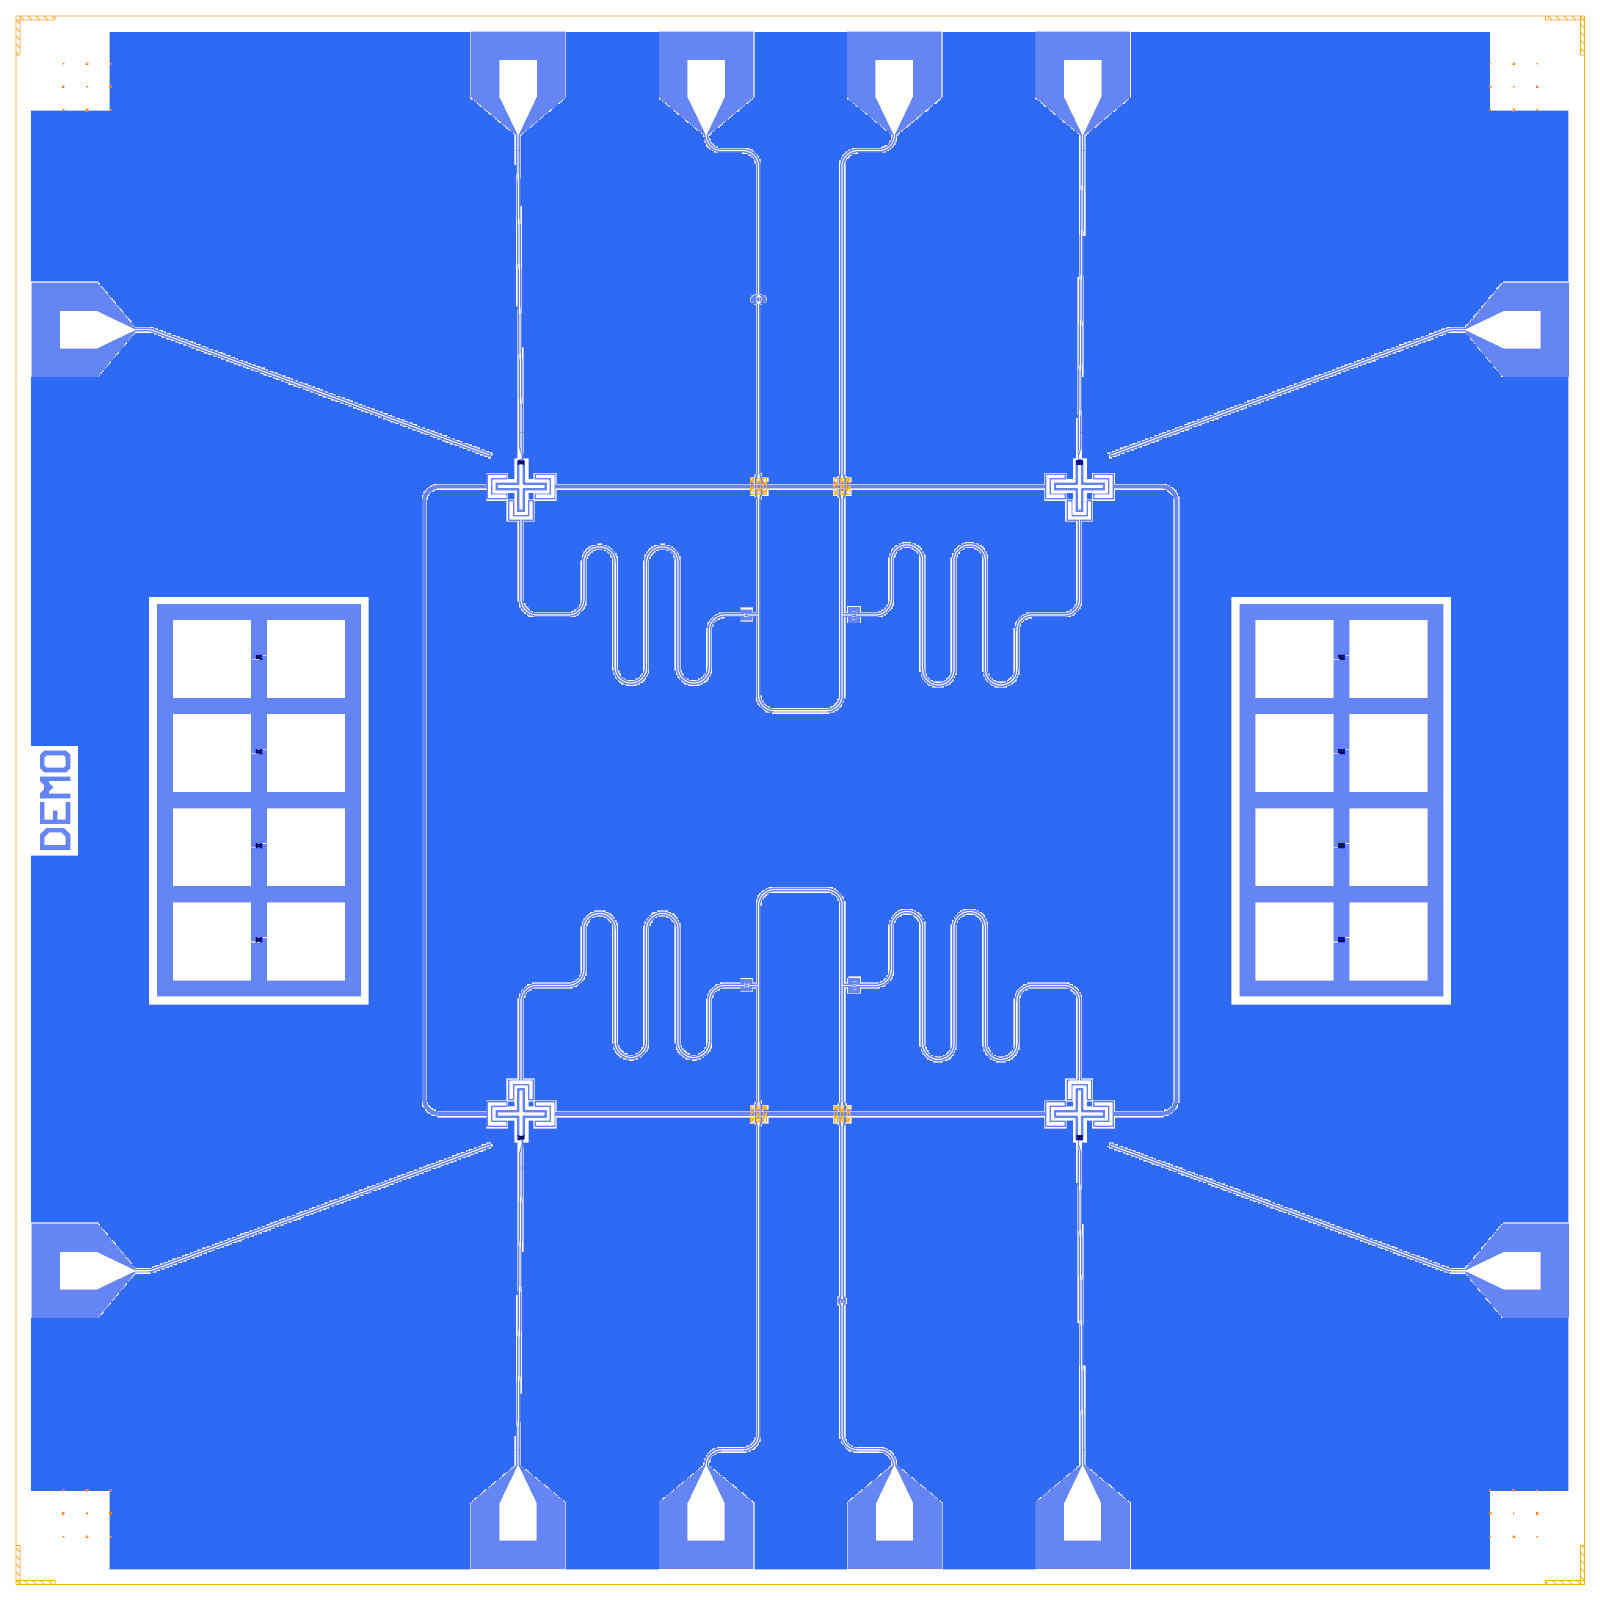

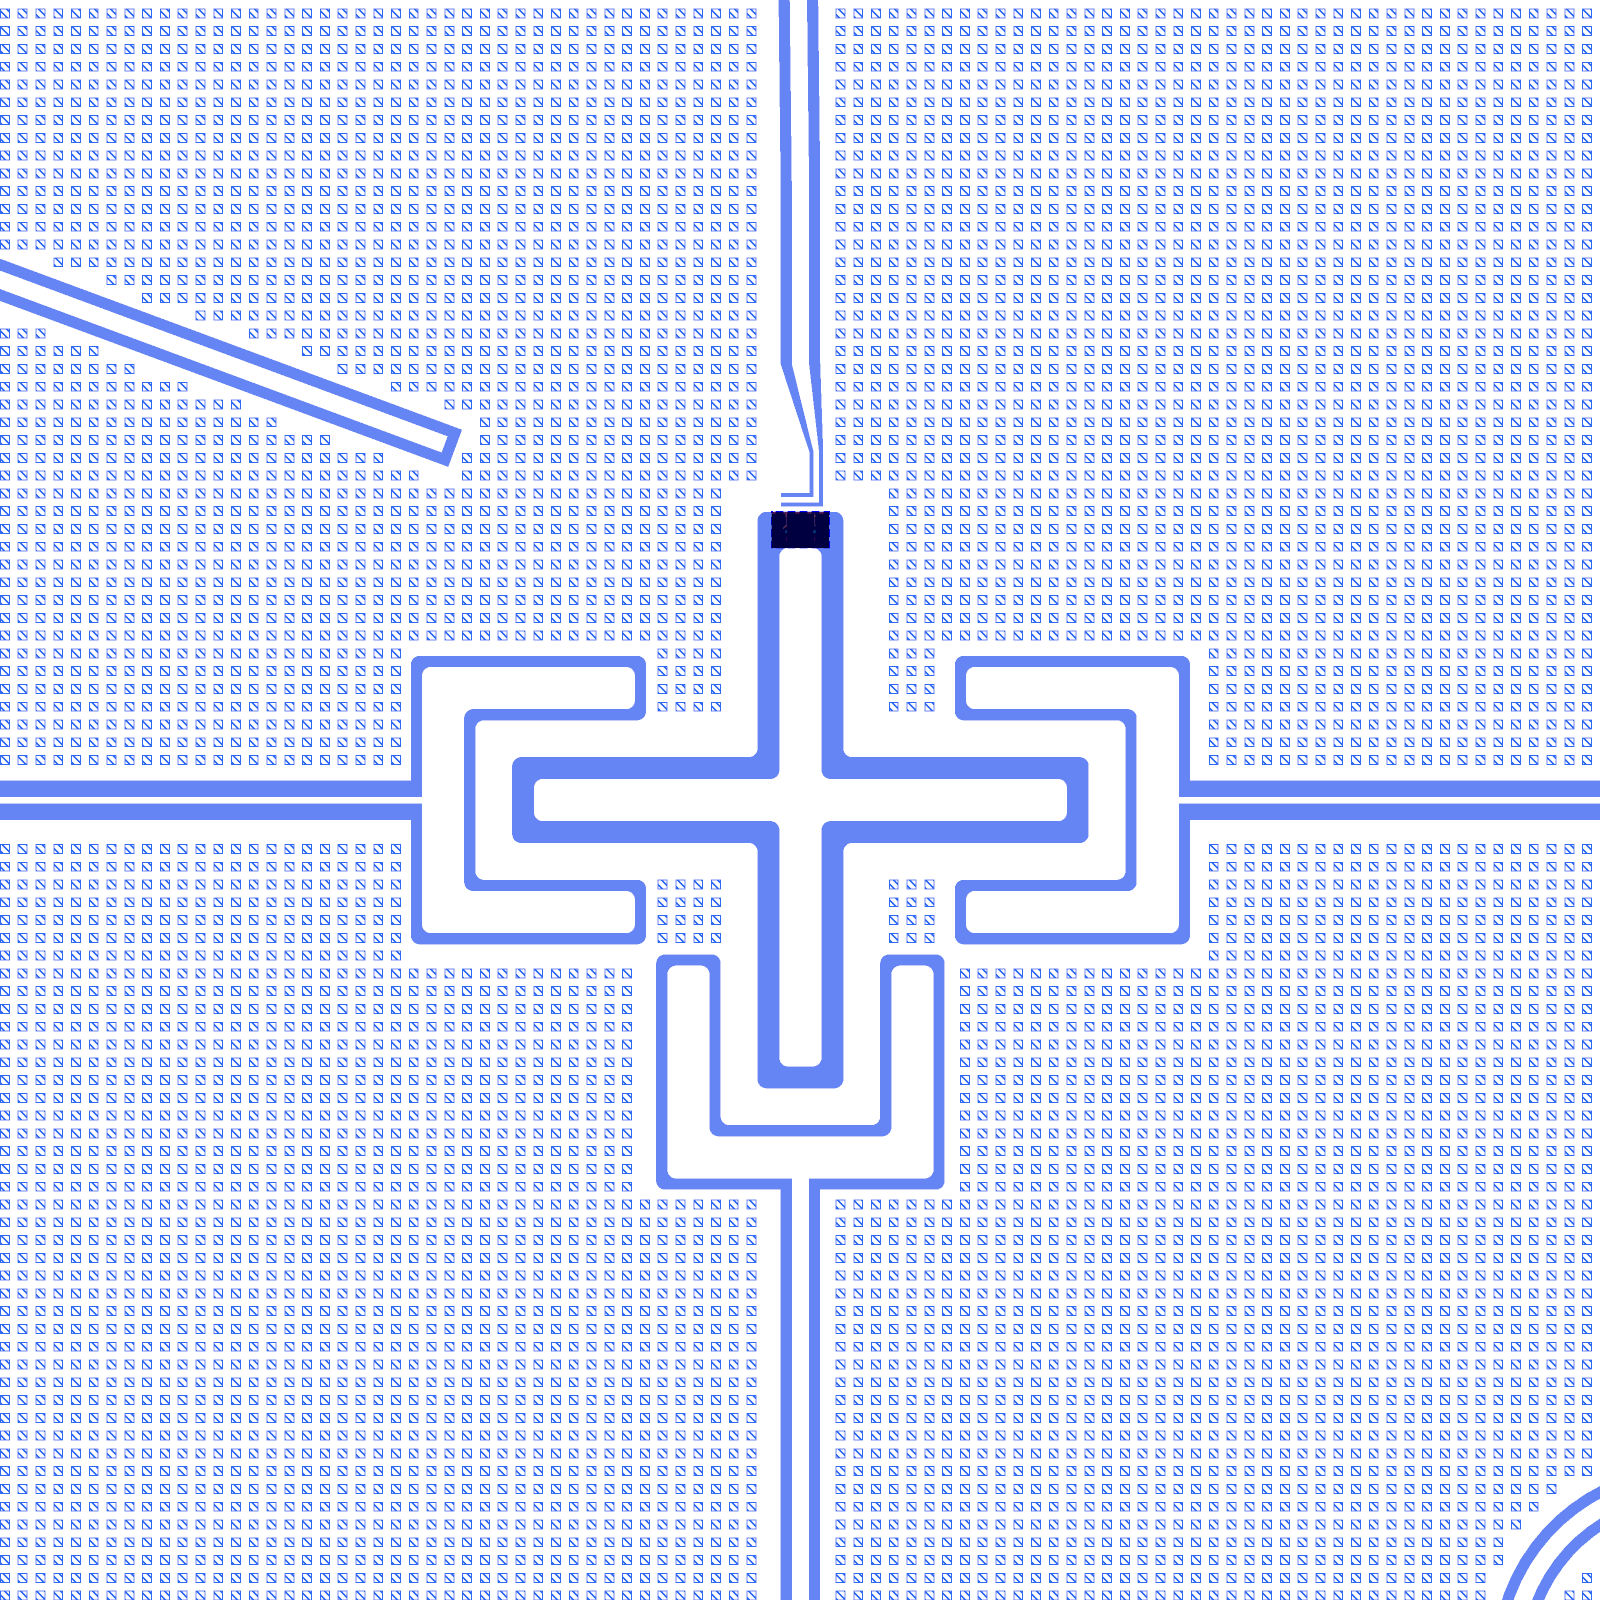

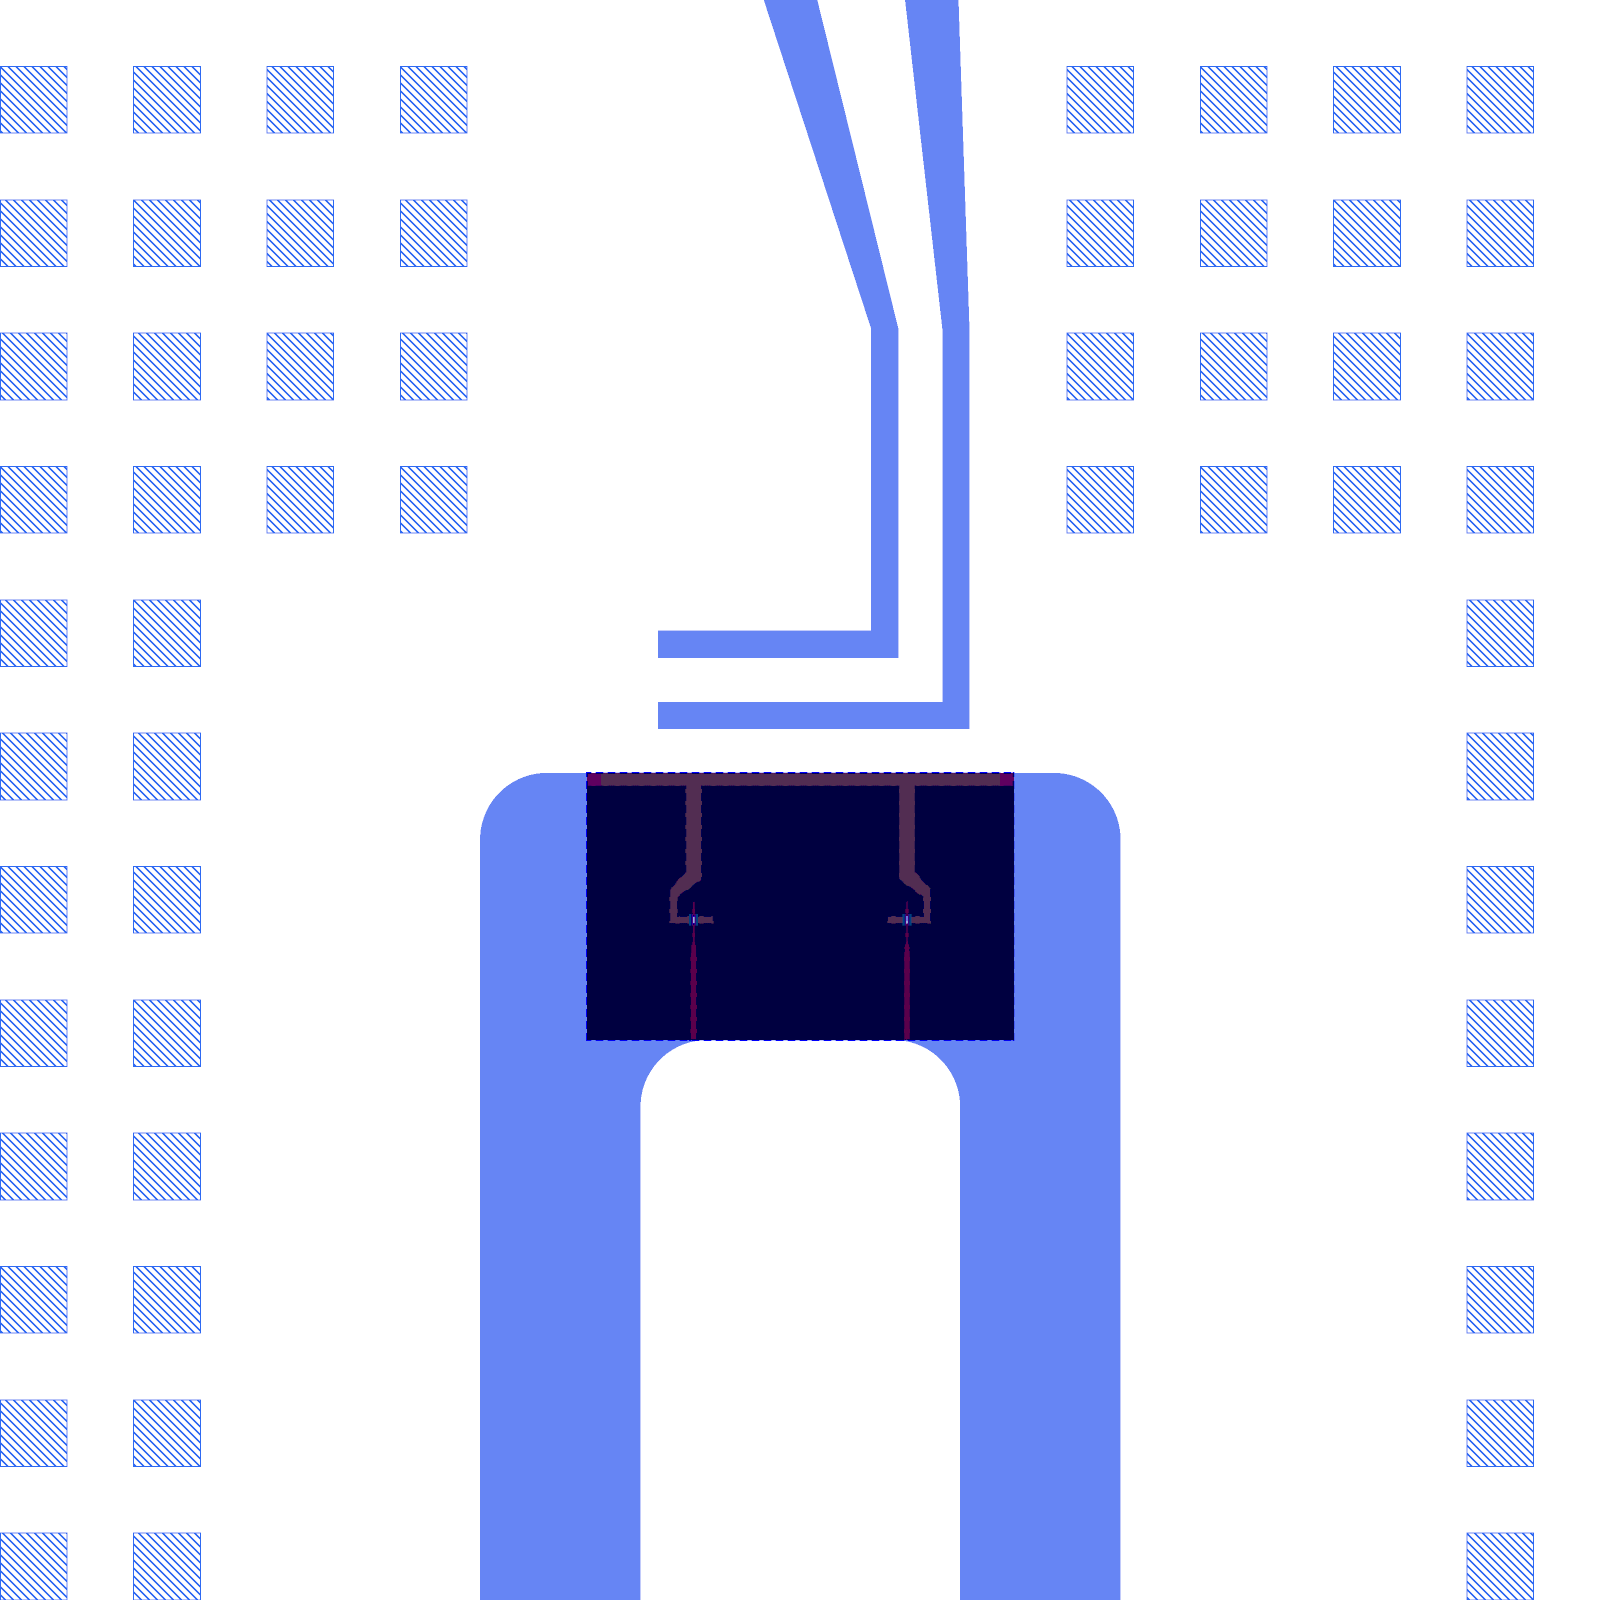

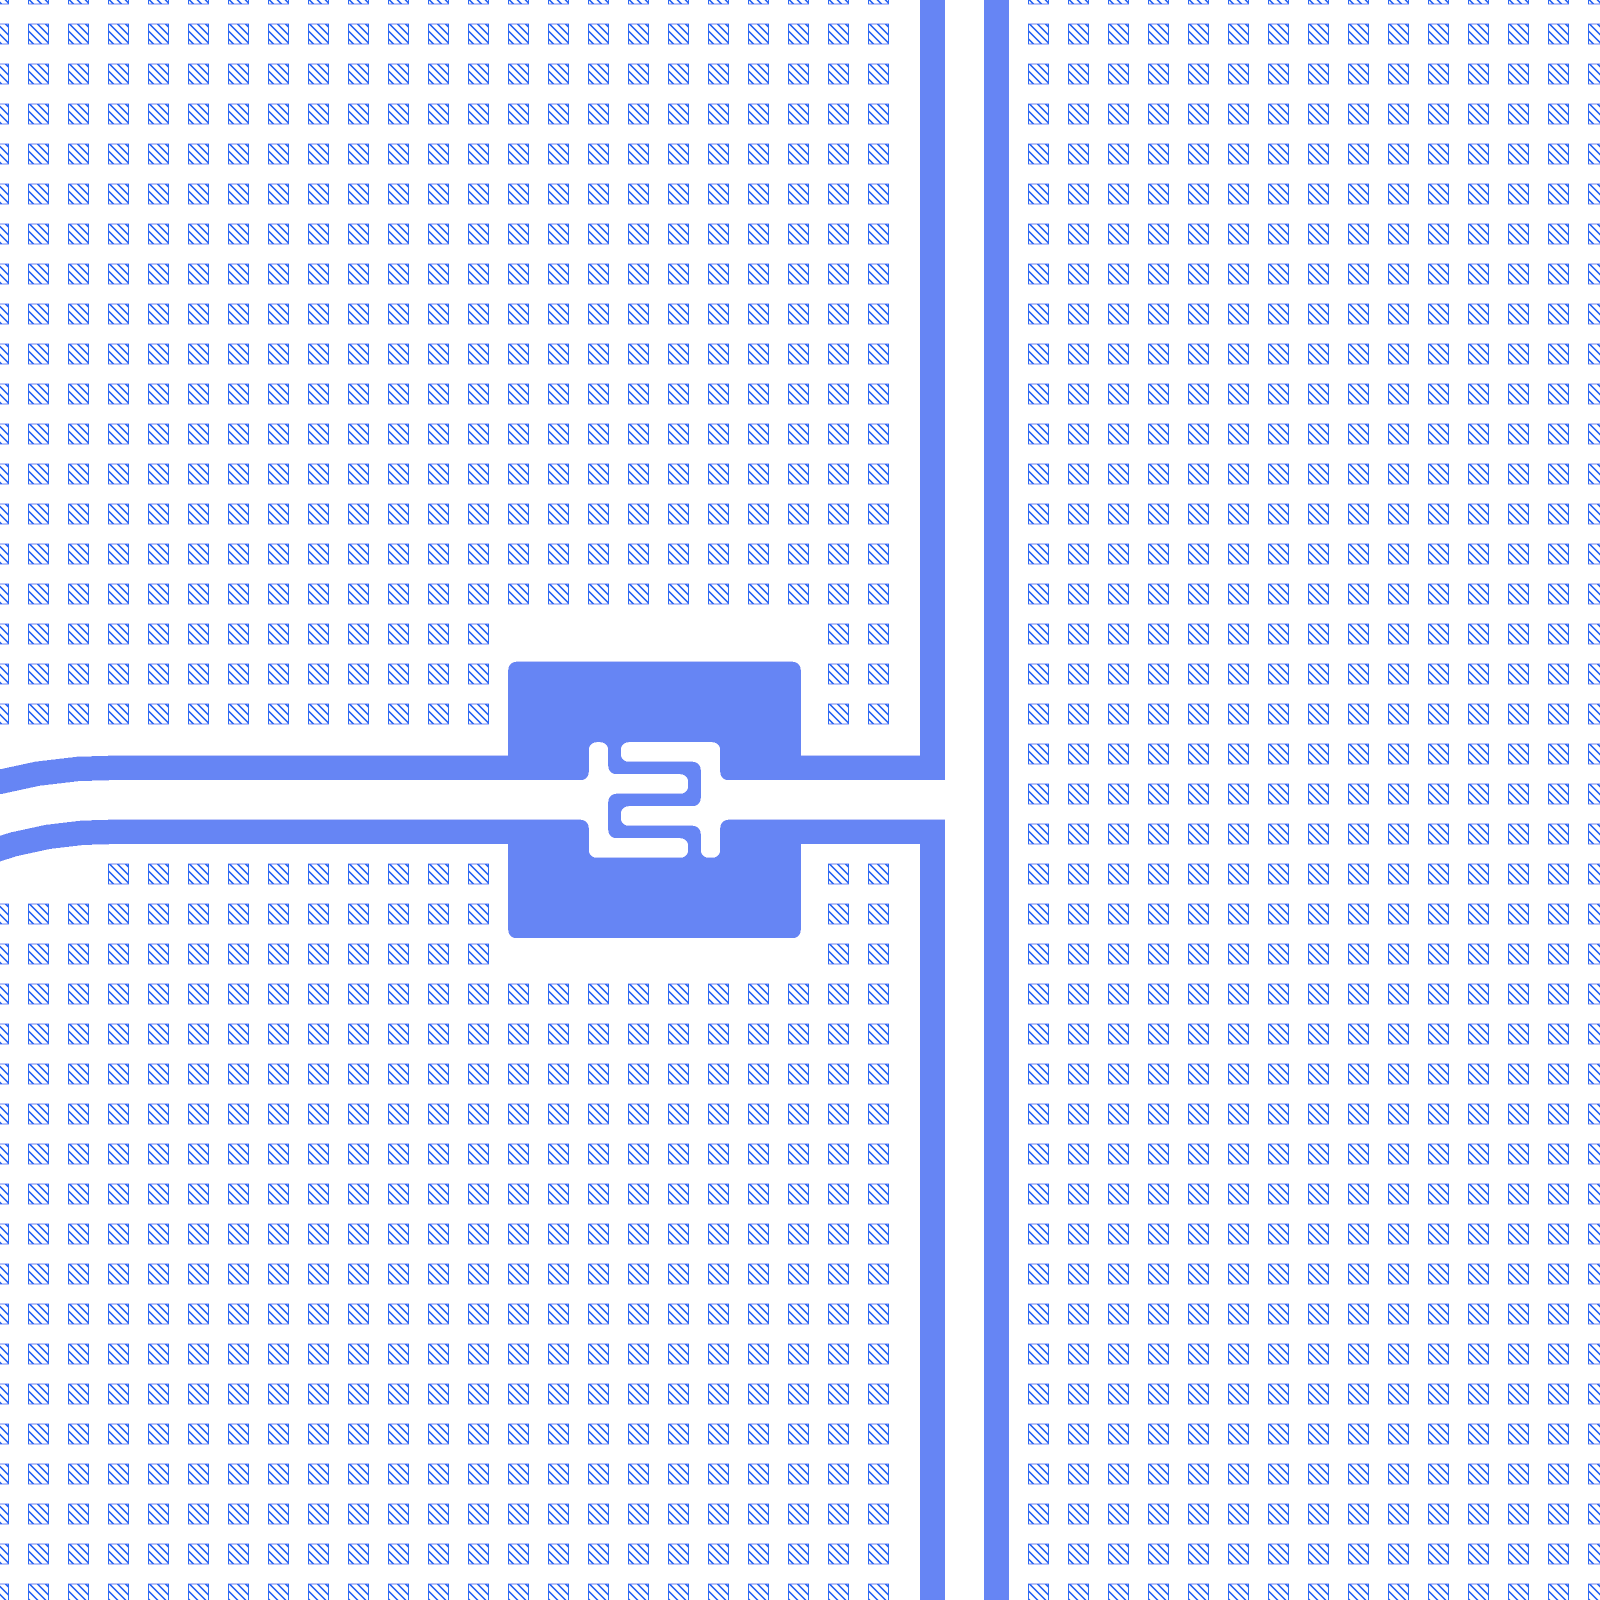

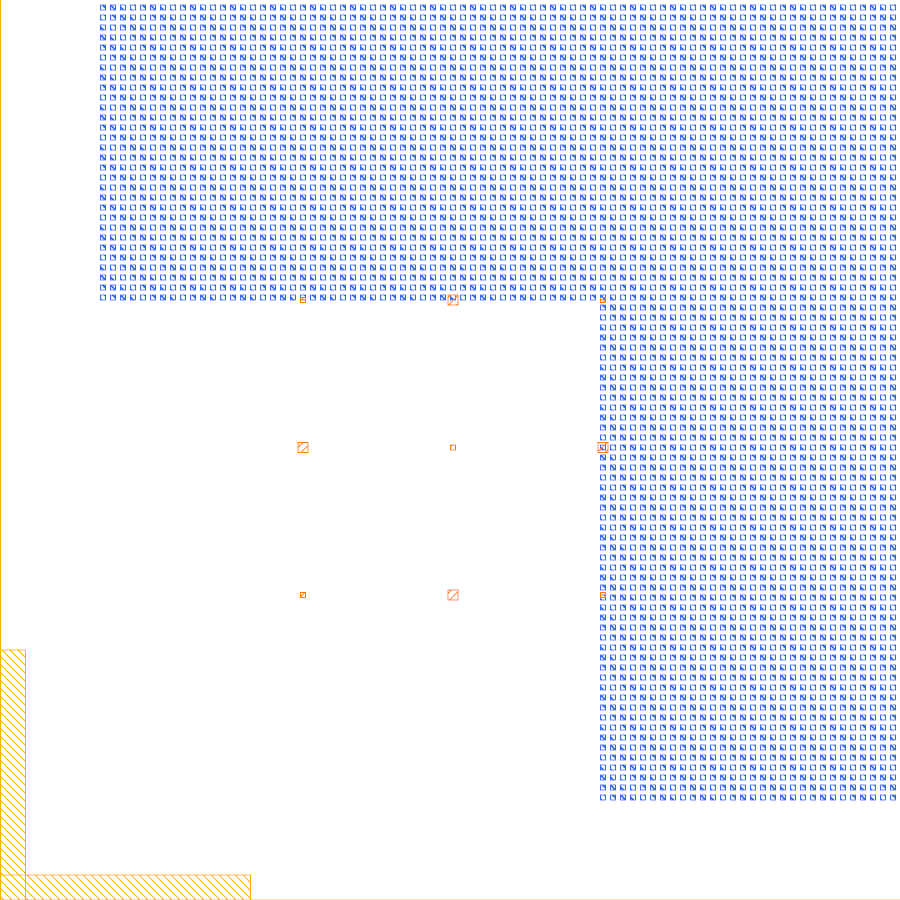

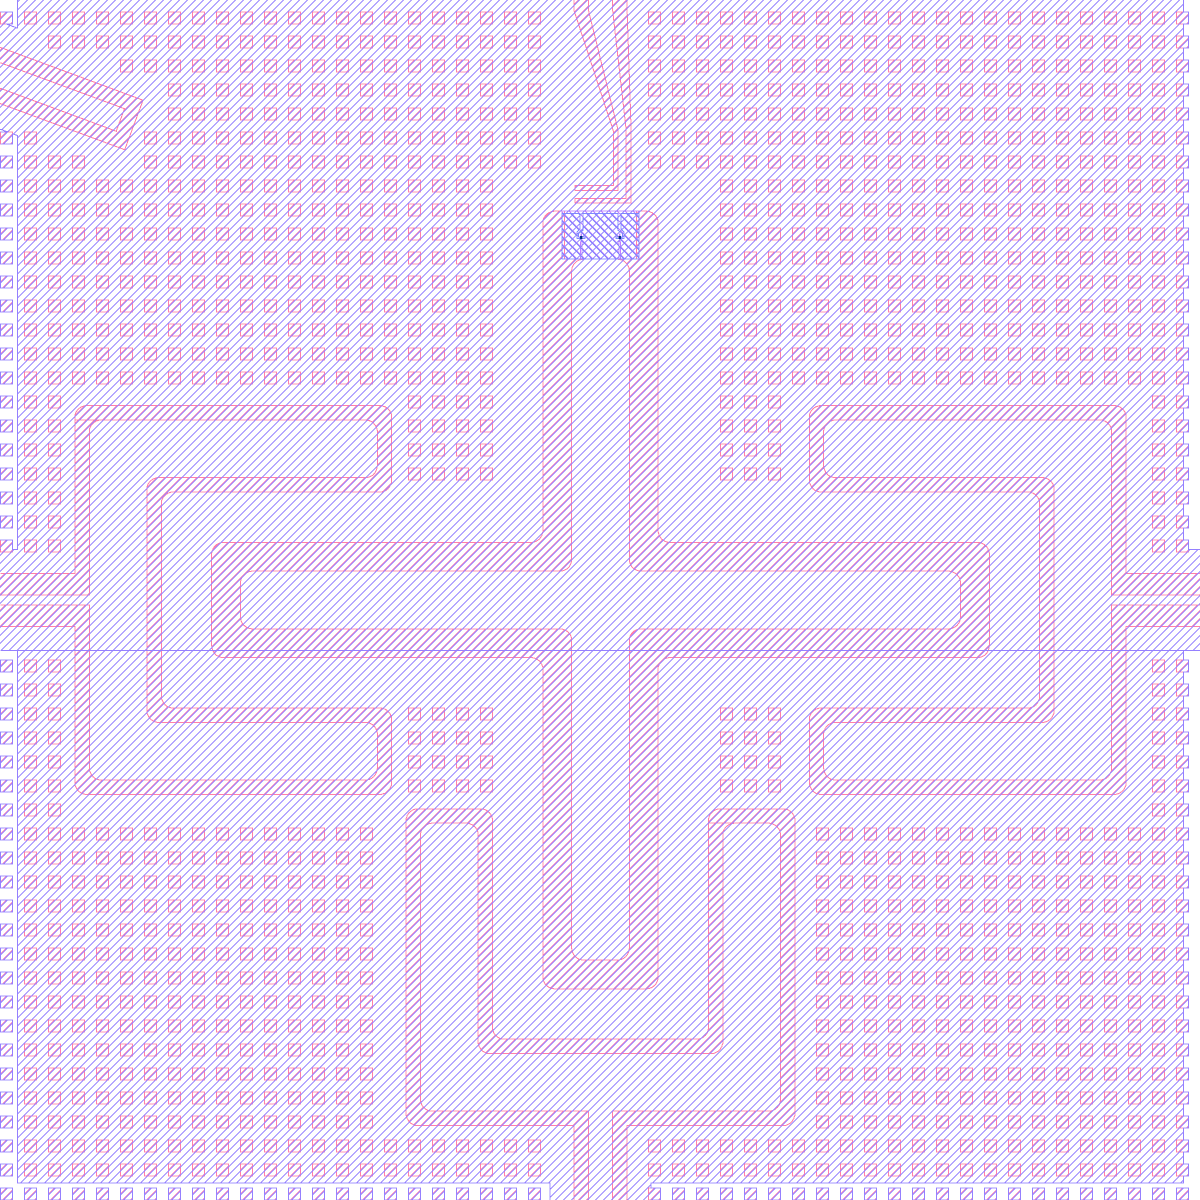

In [21]:
show_snapshot(d, OUT / "demo.png", box=(-100, -100, 10100, 10100))
qx, qy = base["QB1"][:2]
show_snapshot(d, OUT / "demo_qb1.png", box=(qx - 450, qy - 450, qx + 450, qy + 450), width=420)
show_snapshot(d, OUT / "demo_squid.png", box=(qx - 60, qy + 100, qx + 60, qy + 220), width=360)   # SQUID at the top arm tip
cx, cy = port_xy(d, "RC1.b")
show_snapshot(d, OUT / "demo_coupler.png", box=(cx - 200, cy - 200, cx + 200, cy + 200), width=360)
show_snapshot(d, OUT / "demo_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "demo_fab.oas", OUT / "demo_fab_qb1.png", box=(qx - 250, qy - 250, qx + 250, qy + 250),
          size=(1200, 1200), width=420);   # fab view: 1/0 with the grid holes, 3/0, junction layers

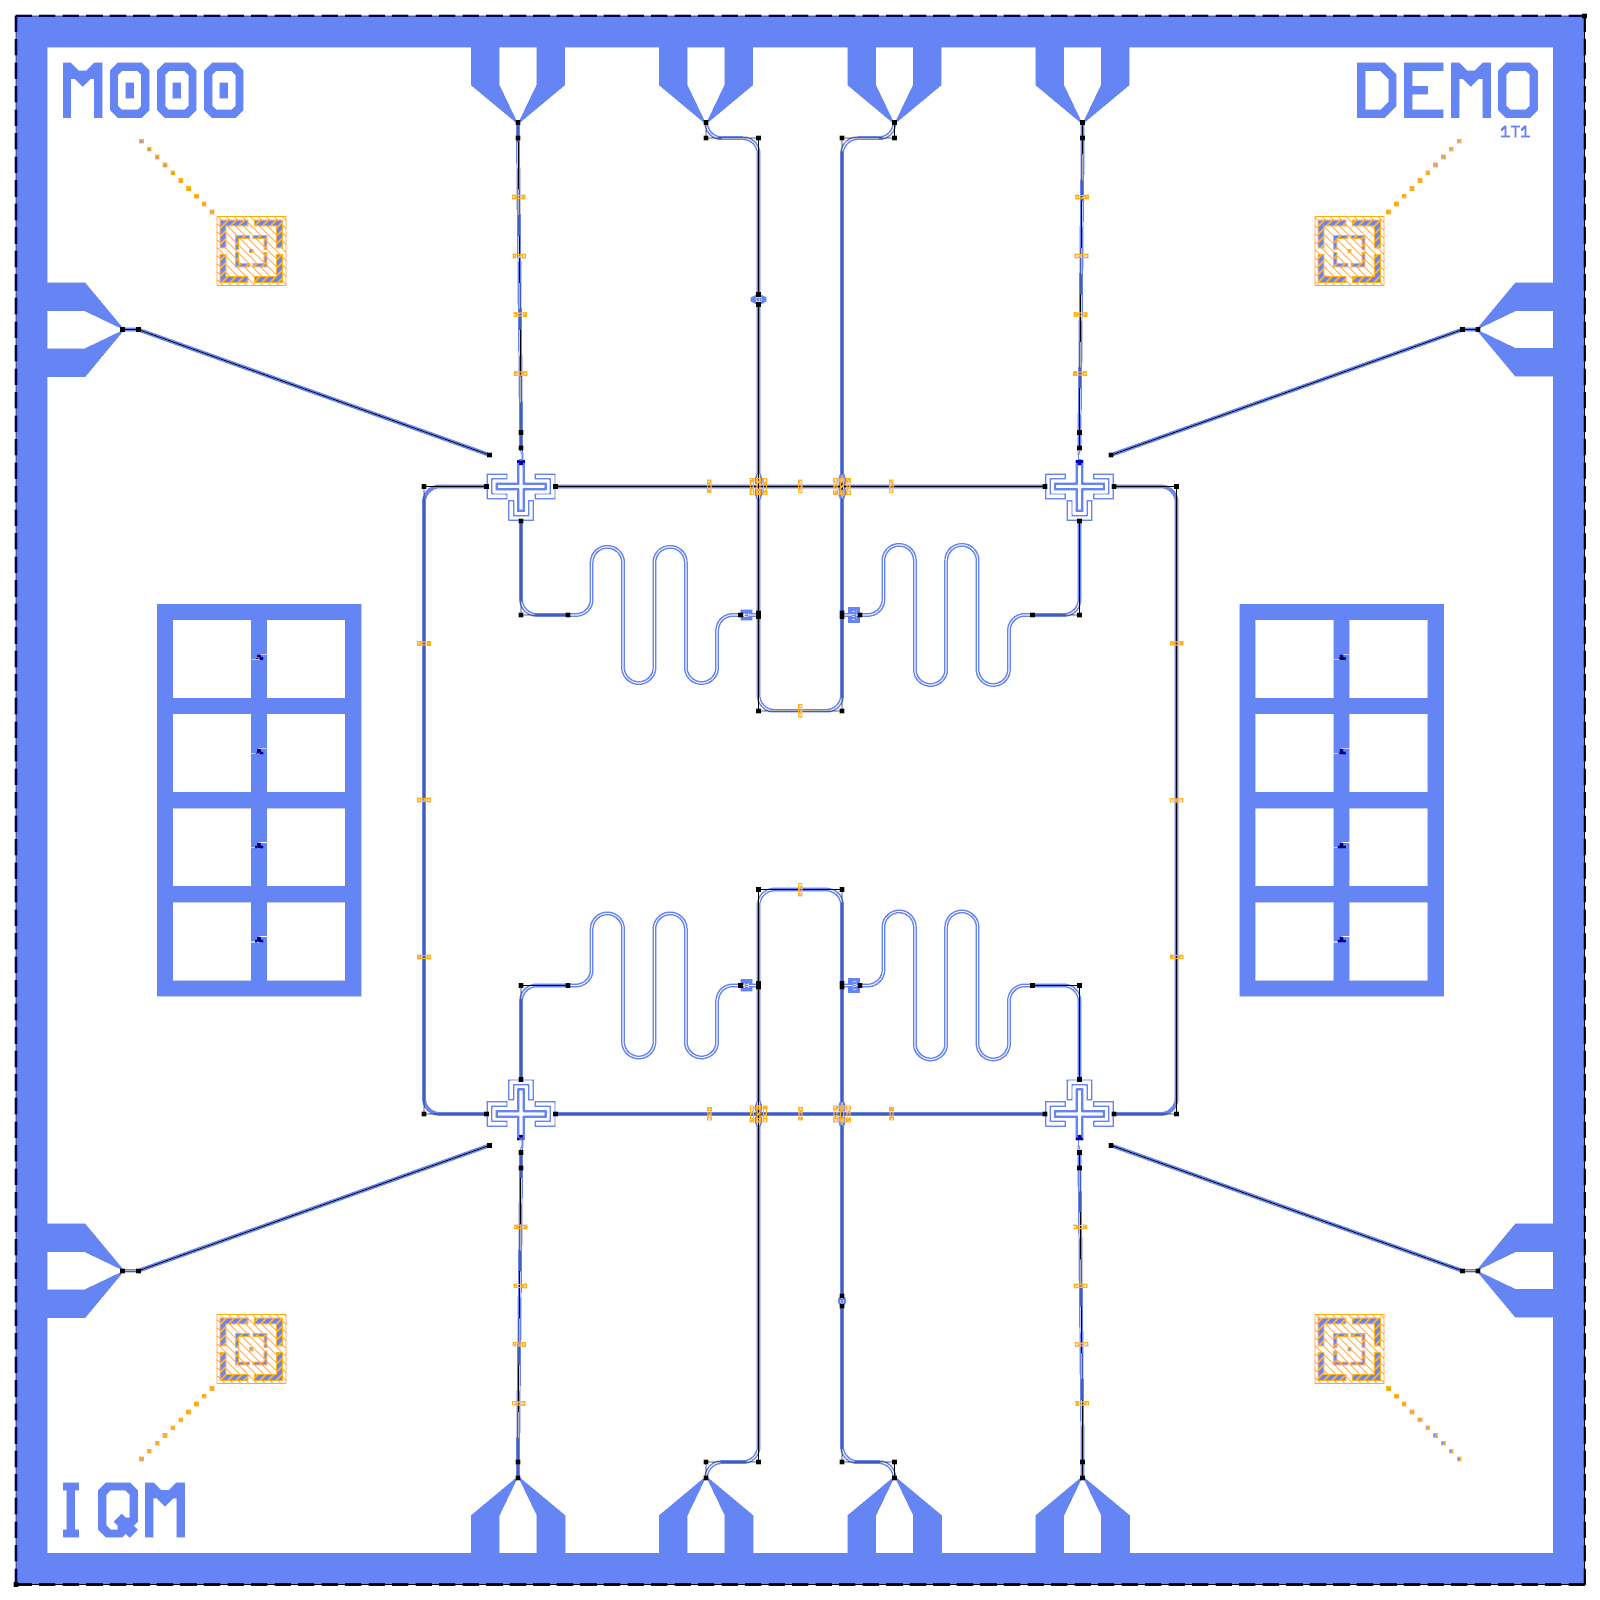

In [22]:
from kqcircuits.chips.demo import Demo
from kqcircuits.pya_resolver import pya

ref = pya.Layout()
top = ref.create_cell("kqc_demo")
top.insert(pya.DCellInstArray(Demo.create(ref).cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "demo_kqc_original.oas"))
snap_file(Path("build") / "demo_kqc_original.oas", OUT / "demo_kqc.png", box=(-100, -100, 10100, 10100), width=420);

## 15 · Summary

| | |
|---|---|
| **matches the source** | every KQC element with its parameters, positions and orientations; the ARD24 launcher assignment; every route's path; readout lengths 5000–5300 µm; the sim groups; KQC's whole-area ground grid |
| **differs (PDK)** | Quantcore die frame instead of KQC's ChipFrame; launchers 79 µm further in (outer etch 100 µm from the edge, `frame.pad_edge`); sapphire instead of silicon; Quantcore trilayer SQUIDs (f_q ≈ 5.8 GHz instead of ≈ 3.9 GHz); waypoints derived from the launcher ports |
| **simplified** | router-fitted readout meanders; no extra `n_bridges` airbridges |
| **PDK design warnings** | as listed in step 7 (the SQUIDs' device R_n, 45 kΩ, is inside the window) |
| **FEM** | 5 Q3D jobs exported (`build/jobs/demo_*`), not solved here |